<a href="https://colab.research.google.com/github/novalrnv/machine_learning/blob/main/JS08/08-Tugas2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Tugas Lab 2 - Clustering HDBSCAN pada Iris Dataset

## Soal 1

Pilih salah satu dataset nyata dari `sklearn.datasets` (misalnya **iris dataset** atau **digits dataset**).

### Jawaban

In [1]:
# Instalasi library hdbscan (tidak tersedia default di sklearn)
!pip install hdbscan

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import hdbscan
from sklearn.datasets import load_iris

# Load dataset iris
iris = load_iris()
X = iris.data
y = iris.target

print('Jumlah data  :', X.shape[0])
print('Jumlah fitur :', X.shape[1])
print('Nama fitur   :', iris.feature_names)
print('Nama kelas   :', list(iris.target_names))

Jumlah data  : 150
Jumlah fitur : 4
Nama fitur   : ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Nama kelas   : [np.str_('setosa'), np.str_('versicolor'), np.str_('virginica')]


**Jawaban:** Dataset yang dipilih adalah **Iris Dataset** dari `sklearn.datasets`, berisi 150 data bunga iris dengan 4 fitur (panjang dan lebar sepal, panjang dan lebar petal) serta 3 kelas asli (setosa, versicolor, virginica) yang masing-masing berjumlah 50 data. Label asli tidak dipakai saat clustering, hanya untuk pembanding pada Soal 4.

## Soal 2

Lakukan clustering dengan HDBSCAN.

### Jawaban

In [2]:
# Clustering dengan HDBSCAN
hdb = hdbscan.HDBSCAN(min_cluster_size=5)
labels = hdb.fit_predict(X)

print('Label hasil clustering:')
print(labels)

Label hasil clustering:
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1]


**Jawaban:** Clustering dilakukan menggunakan `HDBSCAN` dengan `min_cluster_size=5` tanpa memakai label asli. Hasil clustering tersimpan pada variabel `labels`, dengan label `-1` menandakan noise.

## Soal 3

Laporkan hasil: jumlah cluster yang terbentuk, banyaknya noise, dan visualisasi (gunakan PCA/TSNE untuk reduksi dimensi jika perlu).

### Jawaban

In [3]:
# Jumlah cluster dan noise
n_cluster = len(set(labels)) - (1 if -1 in labels else 0)
n_noise = list(labels).count(-1)

print('Jumlah cluster yang terbentuk :', n_cluster)
print('Banyaknya noise               :', n_noise)

Jumlah cluster yang terbentuk : 2
Banyaknya noise               : 0


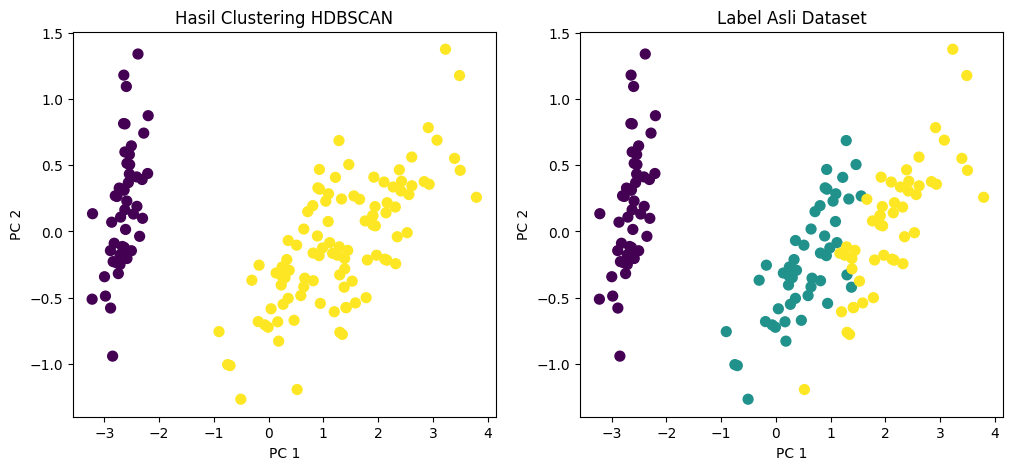

In [4]:
# Visualisasi dengan PCA (4 dimensi -> 2 dimensi)
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Hasil clustering HDBSCAN
axes[0].scatter(X_pca[:, 0], X_pca[:, 1], c=labels, cmap='viridis', s=50)
axes[0].set_title('Hasil Clustering HDBSCAN')
axes[0].set_xlabel('PC 1')
axes[0].set_ylabel('PC 2')

# Label asli
axes[1].scatter(X_pca[:, 0], X_pca[:, 1], c=y, cmap='viridis', s=50)
axes[1].set_title('Label Asli Dataset')
axes[1].set_xlabel('PC 1')
axes[1].set_ylabel('PC 2')

plt.show()

**Jawaban:** HDBSCAN membentuk **2 cluster** dan **0 noise** (semua data masuk ke salah satu cluster). Visualisasi menggunakan PCA yang mereduksi 4 fitur menjadi 2 komponen utama. Grafik kiri adalah hasil clustering HDBSCAN dan grafik kanan adalah label asli, sehingga keduanya bisa dibandingkan langsung.

## Soal 4

Buat analisis singkat: apakah hasil clustering HDBSCAN sesuai dengan label asli dataset tersebut?

### Jawaban

In [5]:
# Bandingkan hasil clustering dengan label asli
tabel = pd.crosstab(iris.target_names[y], labels,
                    rownames=['Label asli'], colnames=['Cluster HDBSCAN'])
print(tabel)

from sklearn.metrics import adjusted_rand_score
print('\nAdjusted Rand Index:', adjusted_rand_score(y, labels))

Cluster HDBSCAN   0   1
Label asli             
setosa           50   0
versicolor        0  50
virginica         0  50

Adjusted Rand Index: 0.5681159420289855


**Jawaban:** Hasil clustering HDBSCAN **sebagian sesuai** dengan label asli.

- Kelas **setosa** terpisah sempurna menjadi satu cluster sendiri (50 data), karena setosa memang jauh terpisah dari dua kelas lainnya.
- Kelas **versicolor** dan **virginica** tergabung menjadi satu cluster (100 data), karena kedua kelas ini saling berdekatan dan sedikit tumpang tindih, sehingga HDBSCAN yang berbasis kepadatan melihatnya sebagai satu wilayah padat.
- Akibatnya, HDBSCAN hanya menemukan 2 cluster, sedangkan label asli ada 3 kelas. Nilai Adjusted Rand Index sebesar sekitar **0.57** menunjukkan kecocokan yang sedang.

**Kesimpulan:** HDBSCAN berhasil menemukan struktur utama data (setosa vs bukan setosa), tetapi tidak dapat memisahkan versicolor dan virginica karena batas kedua kelas tersebut tidak memiliki celah kepadatan yang jelas. Hal ini wajar untuk metode clustering berbasis kepadatan, yang mengelompokkan data berdasarkan kepadatan, bukan berdasarkan label kelas.